In [ ]:
!pip install -q gymnasium

import random
from collections import deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical

In [ ]:
SEEDS = [0, 1, 2, 3, 4]
EPISODES = 500
GAMMA = 0.99

env = gym.make("CartPole-v1")
STATE_DIM = env.observation_space.shape[0]
N_ACTIONS = env.action_space.n

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [ ]:
class PolicyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(STATE_DIM, 128), nn.ReLU(),
            nn.Linear(128, N_ACTIONS), nn.Softmax(dim=-1),
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
class QNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(STATE_DIM, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, N_ACTIONS),
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
def greedy_act(net):
    def act(state):
        with torch.no_grad():
            return net(torch.tensor(state, dtype=torch.float32)).argmax().item()
    return act

def evaluate(act_fn, episodes=20, seed=10_000):
    env = gym.make("CartPole-v1")
    scores = []
    for i in range(episodes):
        state, _ = env.reset(seed=seed + i)
        total, done = 0, False
        while not done:
            state, reward, terminated, truncated, _ = env.step(act_fn(state))
            total += reward
            done = terminated or truncated
        scores.append(total)
    return scores

In [ ]:
LR_PG = 1e-3

def train_reinforce(seed, episodes=EPISODES):
    set_seed(seed)
    env = gym.make("CartPole-v1")
    policy = PolicyNet()
    optimizer = optim.Adam(policy.parameters(), lr=LR_PG)
    history = []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        log_probs, rewards = [], []
        done = False

        while not done:
            probs = policy(torch.tensor(state, dtype=torch.float32))
            dist = Categorical(probs)
            action = dist.sample()
            log_probs.append(dist.log_prob(action))
            state, reward, terminated, truncated, _ = env.step(action.item())
            rewards.append(reward)
            done = terminated or truncated

        returns, G = [], 0
        for r in reversed(rewards):
            G = r + GAMMA * G
            returns.insert(0, G)
        returns = torch.tensor(returns)
        returns = (returns - returns.mean()) / (returns.std() + 1e-8)

        loss = -(torch.stack(log_probs) * returns).sum()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        history.append(sum(rewards))

    return policy, history

In [ ]:
LR_DQN = 5e-4
BATCH_SIZE = 64
BUFFER_SIZE = 10000
EPS_START, EPS_END, EPS_DECAY = 1.0, 0.05, 0.99
TARGET_SYNC = 200
WARMUP = 500
CKPT_EVERY = 10   # greedy check every 10 episodes

def train_dqn(seed, episodes=EPISODES):
    set_seed(seed)
    env = gym.make("CartPole-v1")
    env.action_space.seed(seed)
    q_net, target_net, best_net = QNet(), QNet(), QNet()
    target_net.load_state_dict(q_net.state_dict())
    best_net.load_state_dict(q_net.state_dict())
    optimizer = optim.Adam(q_net.parameters(), lr=LR_DQN)
    buffer = deque(maxlen=BUFFER_SIZE)
    epsilon, steps, history, best_score = EPS_START, 0, [], -1

    for ep in range(episodes):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        total, done = 0, False

        while not done:
            if random.random() < epsilon:
                action = env.action_space.sample()
            else:
                with torch.no_grad():
                    action = q_net(torch.tensor(state, dtype=torch.float32)).argmax().item()

            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            buffer.append((state, action, reward, next_state, float(terminated)))
            state = next_state
            total += reward
            steps += 1

            if len(buffer) >= WARMUP:
                s, a, r, s2, d = zip(*random.sample(buffer, BATCH_SIZE))
                s = torch.tensor(np.array(s), dtype=torch.float32)
                a = torch.tensor(a).unsqueeze(1)
                r = torch.tensor(r, dtype=torch.float32)
                s2 = torch.tensor(np.array(s2), dtype=torch.float32)
                d = torch.tensor(d, dtype=torch.float32)

                q_values = q_net(s).gather(1, a).squeeze(1)
                with torch.no_grad():
                    target = r + GAMMA * target_net(s2).max(1)[0] * (1 - d)

                loss = nn.functional.smooth_l1_loss(q_values, target)
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(q_net.parameters(), 10)
                optimizer.step()

            if steps % TARGET_SYNC == 0:
                target_net.load_state_dict(q_net.state_dict())

        epsilon = max(EPS_END, epsilon * EPS_DECAY)
        history.append(total)

        # Keep the best network, judged on greedy episodes (separate seeds from final evaluation)
        if (ep + 1) % CKPT_EVERY == 0:
            score = np.mean(evaluate(greedy_act(q_net), episodes=5, seed=20_000))
            if score >= best_score:
                best_score = score
                best_net.load_state_dict(q_net.state_dict())

    return q_net, best_net, history

In [ ]:
policies, q_finals, q_bests = [], [], []
reinforce_hist, dqn_hist = [], []

for seed in SEEDS:
    policy, h_r = train_reinforce(seed)
    q_final, q_best, h_d = train_dqn(seed)
    policies.append(policy); q_finals.append(q_final); q_bests.append(q_best)
    reinforce_hist.append(h_r); dqn_hist.append(h_d)
    print(f"Seed {seed} | last-100 avg train reward | "
          f"REINFORCE: {np.mean(h_r[-100:]):.1f} | DQN: {np.mean(h_d[-100:]):.1f}")

Seed 0 | last-100 avg train reward | REINFORCE: 364.5 | DQN: 156.3
Seed 1 | last-100 avg train reward | REINFORCE: 345.4 | DQN: 122.9
Seed 2 | last-100 avg train reward | REINFORCE: 385.0 | DQN: 276.1
Seed 3 | last-100 avg train reward | REINFORCE: 403.7 | DQN: 140.3
Seed 4 | last-100 avg train reward | REINFORCE: 388.6 | DQN: 155.8


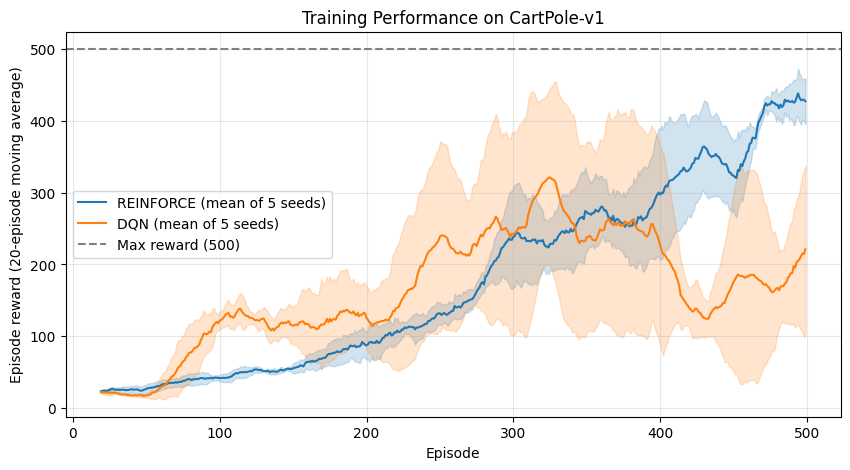

In [ ]:
def moving_avg(x, w=20):
    return np.convolve(x, np.ones(w) / w, mode="valid")

x = np.arange(19, EPISODES)
plt.figure(figsize=(10, 5))
for name, hist, color in [("REINFORCE", reinforce_hist, "tab:blue"),
                          ("DQN", dqn_hist, "tab:orange")]:
    smooth = np.array([moving_avg(h) for h in hist])
    m, s = smooth.mean(axis=0), smooth.std(axis=0)
    plt.plot(x, m, color=color, label=f"{name} (mean of {len(SEEDS)} seeds)")
    plt.fill_between(x, m - s, m + s, color=color, alpha=0.2)

plt.axhline(500, color="gray", linestyle="--", label="Max reward (500)")
plt.xlabel("Episode")
plt.ylabel("Episode reward (20-episode moving average)")
plt.title("Training Performance on CartPole-v1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
eval_scores = {"REINFORCE": [], "DQN (final)": [], "DQN (best ckpt)": []}

for i in range(len(SEEDS)):
    eval_scores["REINFORCE"].append(np.mean(evaluate(greedy_act(policies[i]))))
    eval_scores["DQN (final)"].append(np.mean(evaluate(greedy_act(q_finals[i]))))
    eval_scores["DQN (best ckpt)"].append(np.mean(evaluate(greedy_act(q_bests[i]))))

for name, scores in eval_scores.items():
    print(f"{name:16s} per-seed: {np.round(scores, 1)}")

REINFORCE        per-seed: [500.  500.  500.  500.  406.9]
DQN (final)      per-seed: [500.  409.1 156.2 448.   32.2]
DQN (best ckpt)  per-seed: [500. 500. 500. 500. 500.]


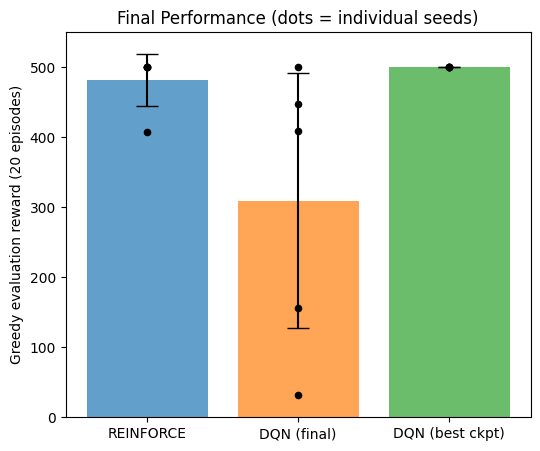

In [ ]:
names = list(eval_scores)
means = [np.mean(eval_scores[n]) for n in names]
stds = [np.std(eval_scores[n]) for n in names]

plt.figure(figsize=(6, 5))
plt.bar(names, means, yerr=stds, capsize=8, alpha=0.7,
        color=["tab:blue", "tab:orange", "tab:green"])
for i, n in enumerate(names):
    plt.scatter([i] * len(SEEDS), eval_scores[n], color="black", s=20, zorder=3)
plt.ylabel("Greedy evaluation reward (20 episodes)")
plt.title("Final Performance (dots = individual seeds)")
plt.ylim(0, 550)
plt.show()

In [ ]:
import pandas as pd

train_last100 = {
    "REINFORCE": [np.mean(h[-100:]) for h in reinforce_hist],
    "DQN (final)": [np.mean(h[-100:]) for h in dqn_hist],
}

rows = []
for name, scores in eval_scores.items():
    train = train_last100.get(name)
    rows.append({
        "Agent": name,
        "Eval mean": np.mean(scores),
        "Eval std (across seeds)": np.std(scores),
        "Seeds scoring >= 475": int(np.sum(np.array(scores) >= 475)),
        "Train reward (last 100 eps)": np.mean(train) if train else np.nan,
    })

pd.DataFrame(rows).round(1)

,Agent,Eval mean,Eval std (across seeds),Seeds scoring >= 475,Train reward (last 100 eps)
0,REINFORCE,481.4,37.2,4,377.4
1,DQN (final),309.1,182.1,1,170.3
2,DQN (best ckpt),500.0,0.0,5,NaN


**REINFORCE** trained stably, with 4 of 5 seeds reaching the maximum greedy score and the fifth reaching 407. **DQN**’s final networks were far more variable (32 to 500), consistent with instability from bootstrapped targets and a moving target network. With best-checkpoint selection, **DQN** reached 500 on all seeds, so its weakness here is retaining a good policy rather than finding one. **REINFORCE** is simpler and more stable but higher-variance per update; **DQN** is off-policy and can reuse data, but needs stabilisation tricks or checkpointing to be reliable.